# **Pós-Graduação em Data Science and Digital Transformation**

## *Análise de Dados e Aprendizagem Automática*

Ana Estreia
---
### Trabalho prático 1
O objetivo deste trabalho é utilizar as técnicas e os algoritmos aprendidos até à data para treinar e testar modelos de regressão. É usado o conjunto de dados denominado DNA_Methylation.csv , com o objetivo de prever a idade cronológica correspondente aos vários atributos.
O conjunto de dados contém 13 atributos que correspondem à análise sanguínea de diferentes marcadores da reação de metilação do ADN humano. As características desta reação vão-se alterando com a idade, pelo que ela é um bom biomarcador da idade cronológica. A última coluna do conjunto de dados é a idade, que será utilizada como alvo.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

In [ ]:
dados = pd.read_csv("DNA_Methylation.csv")

In [ ]:
print("Número de linhas: ",dados.shape[0])
print("Número de colunas: ", dados.shape[1])

Número de linhas:  312
Número de colunas:  14


In [ ]:
dados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 312 entries, 0 to 311
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   RPA2_3     312 non-null    float64
 1   ZYG11A_4   312 non-null    float64
 2   F5_2       312 non-null    float64
 3   HOXC4_1    312 non-null    float64
 4   NKIRAS2_2  312 non-null    float64
 5   MEIS1_1    312 non-null    float64
 6   SAMD10_2   312 non-null    float64
 7   GRM2_9     312 non-null    float64
 8   TRIM59_5   312 non-null    float64
 9   LDB2_3     312 non-null    float64
 10  ELOVL2_6   312 non-null    float64
 11  DDO_1      312 non-null    float64
 12  KLF14_2    312 non-null    float64
 13  Age        312 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 34.3 KB


Verifica-se que não existem valores nulos. Logo, todas as células do DataFrame estão devidamente preenchidas.  
Todas as colunas são do tipo numérico.

In [ ]:
dados.describe()

,RPA2_3,ZYG11A_4,F5_2,HOXC4_1,NKIRAS2_2,MEIS1_1,SAMD10_2,GRM2_9,TRIM59_5,LDB2_3,ELOVL2_6,DDO_1,KLF14_2,Age
count,312.000000,312.000000,312.000000,312.000000,312.000000,312.000000,312.000000,312.000000,312.000000,312.000000,312.000000,312.000000,312.000000,312.000000
mean,63.421346,17.510224,38.417821,46.151667,24.714744,44.210801,35.059808,43.224423,44.701474,56.697756,56.547756,47.855000,3.022468,43.528846
std,7.655321,5.819024,6.283198,9.003114,4.358336,14.183003,5.994066,17.219455,8.409994,10.084836,10.781130,13.985925,1.835966,15.001580
min,43.780000,6.220000,23.580000,23.280000,12.070000,12.760000,18.220000,5.400000,24.320000,31.940000,31.830000,14.770000,0.480000,18.000000
25%,58.200000,13.297500,33.597500,39.212500,21.717500,33.642500,30.692500,29.562500,38.287500,49.267500,48.312500,38.922500,1.637500,31.000000
50%,63.675000,17.190000,37.970000,46.235000,24.405000,44.900000,34.965000,43.785000,44.265000,57.270000,57.740000,47.320000,2.525000,43.500000
75%,68.590000,21.022500,42.920000,52.905000,27.640000,53.607500,39.540000,56.707500,51.365000,64.110000,64.965000,56.587500,4.140000,56.250000
max,85.480000,40.820000,52.120000,69.470000,38.540000,79.270000,50.390000,82.090000,69.960000,81.780000,77.160000,88.090000,9.230000,69.000000


In [ ]:
dados_num=dados.select_dtypes(include='number')
#sns.heatmap(dados_num.corr(), annot = True)

In [ ]:
sns.pairplot(dados)

Output hidden; open in https://colab.research.google.com to view.

## 1. Regressão Linear 1
Modelo de regressão linear base, usando todos os 13 atributos sanguíneos disponíveis para prever a idade.

In [ ]:
performance = pd.DataFrame(columns=["train R2", "test R2", "MAE", "RMSE"])

In [ ]:
# Separar as variáveis independentes (X) do alvo (y)
X = dados.drop('Age', axis=1)
y = dados[['Age']]

In [ ]:
# Dividir dados de treino e teste (random_state=0 garante a reprodutibilidade)
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, train_size=0.8, test_size=0.2, random_state=0)

# Criar e treinar o modelo
modelo_linear = LinearRegression()
modelo_linear.fit(Xtrain, ytrain)

LinearRegression()

In [ ]:
def avaliar_modelo(nome_do_modelo, r2_treino, ytest, ypred):
    ''' Função que calcula as métricas de avaliação de um modelo de regressão.
        Recebe a designação do modelo, a variável alvo  e as previsões
        e determina as métricas mae, rmse e coeficiente de determinação, R2.
        Por fim, atualiza o DF de performance com os resultados.
    '''
    mae = mean_absolute_error( ytest, ypred )
    rmse = mean_squared_error( ytest, ypred)**0.5 #raiz quadrada de mse
    r2 = r2_score( ytest, ypred )
    print(f"Erro  absoluto médio  = {mae:.2f}")
    print(f"Raiz do erro  quadrático médio  = {rmse:.2f}")
    print(f"Teste: r2: {r2:.2f}")
    #atualizar pd performance
    performance.loc[nome_do_modelo,["train R2", "test R2", "MAE", "RMSE"]]= [f'{r2_treino:.2f}',
                                         f'{r2:.2f}', f'{mae:.2f}', f'{rmse:.2f}']

In [ ]:
#R2 de treino
r2_treino = modelo_linear.score(Xtrain,ytrain)
#calcular as previsões
y_pred = modelo_linear.predict(Xtest)
#determina as métricas de teste e regista
avaliar_modelo("Regressão Linear Global",r2_treino, ytest, y_pred)
performance

Erro  absoluto médio  = 3.43
Raiz do erro  quadrático médio  = 4.21
Teste: r2: 0.92


,train R2,test R2,MAE,RMSE
Regressão Linear Global,0.94,0.92,3.43,4.21


O modelo apresenta uma excelente performance no conjunto de teste, com um valor de $R^2$ a rondar os $0.92$ (o modelo explica aproximadamente 92% da variância da Idade com base na metilação do ADN).

Isto comprova que estes marcadores são, de facto, ótimos biomarcadores para a idade cronológica.

## 2. Regressão Linear 2

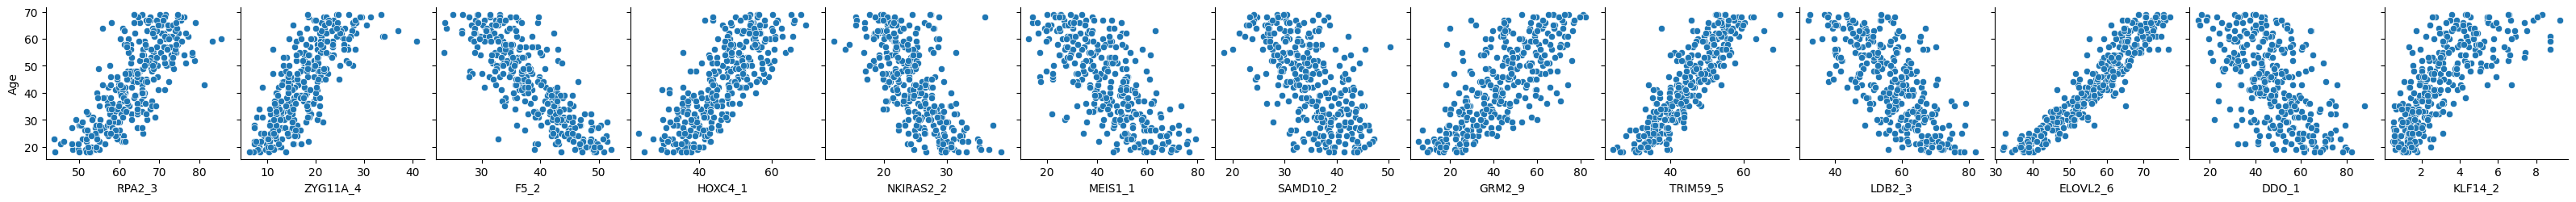

In [ ]:
sns.pairplot(dados, x_vars=X.columns, y_vars=['Age'])
plt.show()

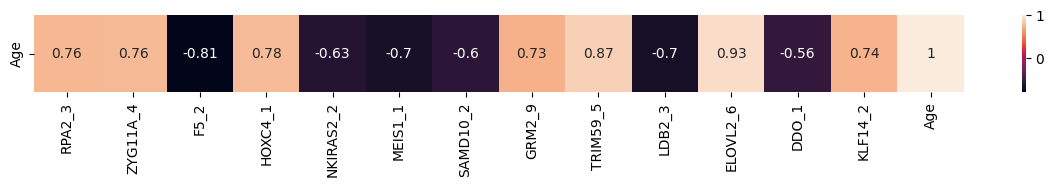

In [ ]:
corr_matrix = dados_num.corr()
age_correlations = corr_matrix.loc[['Age']]

plt.figure(figsize=(15, 1)) # Adjust figure size for a single row
sns.heatmap(age_correlations, annot=True)
plt.show()

Vamos excluir os atributos **KLF14_2** e **DDO_1**.


**DDO_1**:  É o atributo que apresenta a correlação mais fraca com o alvo Age (aproximadamente $-0.56$ absoluto). Sendo o marcador com menor impacto linear, a sua remoção alivia o modelo de variáveis menos relevantes.

**KLF14_2**: Embora tenha uma boa correlação com a idade (aproximadamente $0.74$), a relação entre a metilação do KLF14_2 e a idade cronológica não é estritamente linear, mas sim uma curva.

In [ ]:
X2 = X.copy()
X2.drop(['DDO_1','KLF14_2'], axis=1, inplace=True)


In [ ]:
X2.head()

,RPA2_3,ZYG11A_4,F5_2,HOXC4_1,NKIRAS2_2,MEIS1_1,SAMD10_2,GRM2_9,TRIM59_5,LDB2_3,ELOVL2_6
0,52.36,11.95,47.48,36.08,35.10,70.16,43.46,23.31,33.64,74.44,36.12
1,59.44,21.49,41.19,39.51,30.15,58.90,27.73,53.05,35.94,66.46,45.35
2,67.84,17.43,38.29,47.76,21.82,43.83,23.28,37.69,47.76,54.00,59.20
3,67.68,19.64,30.53,43.83,22.08,31.06,30.25,44.54,53.88,31.94,64.33
4,70.51,30.56,31.76,69.47,20.55,21.64,26.18,68.05,51.74,48.22,71.09


In [ ]:
X2_train, X2_test, ytrain, ytest = train_test_split(
    X2, y, train_size=0.8, test_size=0.2,random_state=0)

In [ ]:
modelo_linear2 = LinearRegression()
modelo_linear2.fit(X2_train, ytrain)

LinearRegression()

In [ ]:
#R2 de treino
r2_treino2 = modelo_linear2.score(X2_train,ytrain)
#calcular as previsões
y2_pred = modelo_linear2.predict(X2_test)
#determina as métricas de teste e regista
avaliar_modelo("Regressão Linear Reduzida",r2_treino2, ytest, y2_pred)
performance

Erro  absoluto médio  = 3.64
Raiz do erro  quadrático médio  = 4.29
Teste: r2: 0.91


,train R2,test R2,MAE,RMSE
Regressão Linear Global,0.94,0.92,3.43,4.21
Regressão Linear Reduzida,0.94,0.91,3.64,4.29


Embora o segundo modelo (Reduzido) apresente valores de erro ligeiramente superiores e uma pequena redução na precisão de teste, a diferença não é significativa.

Esta proximidade mostra que ambos modelos são robustos, ainda que o segunto contenha menos informação.

## 3. Regressão Polinomial
Criar um modelo de regressão polinomial com o atributo **KLF14_2**.

In [ ]:
X_klf = dados[['KLF14_2']]


In [ ]:
pf = PolynomialFeatures(degree=2)
Xpoli = pf.fit_transform(X_klf)

In [ ]:
Xpoli =  pd.DataFrame(Xpoli, index=X.index, columns=["klf^0", "klf^1", "klf^2"])
Xpoli.head()

,klf^0,klf^1,klf^2
0,1.0,2.46,6.0516
1,1.0,1.77,3.1329
2,1.0,2.00,4.0000
3,1.0,5.44,29.5936
4,1.0,4.48,20.0704


In [ ]:
Xpoli_train, Xpoli_test, ytrain, ytest = train_test_split(Xpoli, y, train_size=.8,
                                                         test_size=.2, random_state = 0)

In [ ]:
pol_reg = LinearRegression()
pol_reg.fit(Xpoli_train, ytrain)

LinearRegression()

In [ ]:
#determinar R2 de treino
r2_treino_poli = pol_reg.score(Xpoli_train,ytrain)
#previsão
ypoli_pred = pol_reg.predict(Xpoli_test)

# avaliação do modelo
avaliar_modelo("Regressão Polinomial",r2_treino_poli, ytest, ypoli_pred)
performance

Erro  absoluto médio  = 8.14
Raiz do erro  quadrático médio  = 10.08
Teste: r2: 0.52


,train R2,test R2,MAE,RMSE
Regressão Linear Global,0.94,0.92,3.43,4.21
Regressão Linear Reduzida,0.94,0.91,3.64,4.29
Regressão Polinomial,0.64,0.52,8.14,10.08


O modelo polinomial criado com o atributo KLF14_2, regista valores de erro superiores e um $R^2$ inferior aos dos modelos construídos nas alíneas anteriores. No entanto, é um resultado esperado, uma vez que estamos a tentar prever a Idade com base num único biomarcador isolado.

In [ ]:
#transformar predições em DataFrame e atribuir mesmo índice de Xpoli_test
ypoli_pred = pd.DataFrame(ypoli_pred, index=Xpoli_test.index, columns=["ypoli_pred"])
ypoli_pred.head()

,ypoli_pred
65,36.460473
225,33.417212
188,60.360299
200,59.797313
108,41.867502


In [ ]:
#Criar  DF com dados, ytest  e predições
#para usar no gráfico

out = Xpoli_test.drop(["klf^0", "klf^2"], axis=1)

out = out.join(ytest)

out = out.join(ypoli_pred)
out.head()

,klf^1,Age,ypoli_pred
65,1.86,43,36.460473
225,1.57,48,33.417212
188,5.44,68,60.360299
200,5.27,59,59.797313
108,2.42,48,41.867502


In [ ]:
#ordenar de acordo com os valores de KLF14_2,
#que vão ser representados no eixo horizontal do gráfico de dispersão
out.sort_values(by="klf^1", inplace=True)
out.head()

,klf^1,Age,ypoli_pred
231,0.55,26,21.395057
248,0.56,22,21.522886
55,0.67,34,22.915979
212,0.90,24,25.751660
5,0.98,20,26.713516


In [ ]:
r2=r2_score(ytest, ypoli_pred)

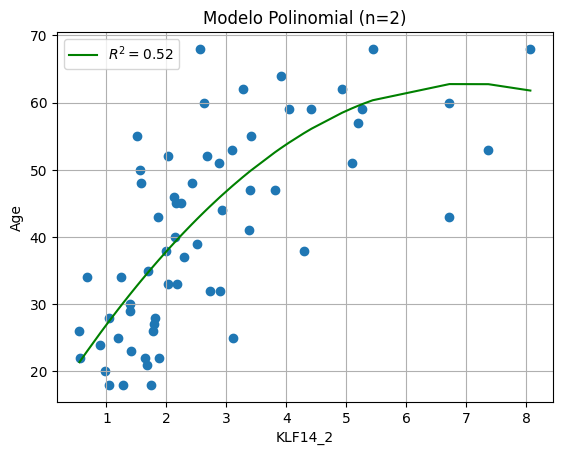

In [ ]:
fig, ax = plt.subplots()
ax.grid()
#gráfico de dispersão entre o consumo combinado e as emissões
ax.scatter(out["klf^1"],out["Age"])
#linha com o modelo
ax.plot(out["klf^1"], out["ypoly_pred"], '-g', label="$R^2={:.2f}$".format(r2))
ax.set_xlabel("KLF14_2")
ax.set_ylabel("Age")
ax.set_title("Modelo Polinomial (n=2)")
ax.legend()

Utilização de pipelines para optimizar o grau do polinómio na regressão polinomial com o atributo *KLF14_2*.
O transformador é `PolinomialFeatures(n)` e o modelo é `LinearRegression()`


/tmp/ipykernel_724/496155071.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


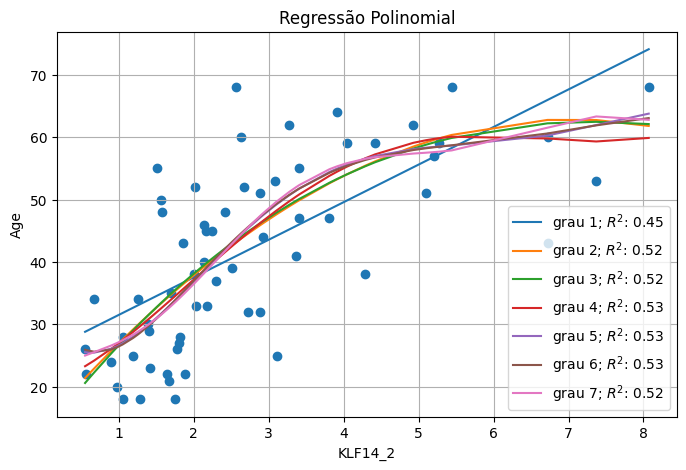

In [ ]:
#gráficos
fig, ax = plt.subplots(figsize=(8,5))
ax.scatter(out["klf^1"],out["Age"])
ax.set_title("Regressão Polinomial")
ax.set_xlabel("KLF14_2")
ax.set_ylabel("Age")
ax.legend()
ax.grid()

#fazer primeiro separação treino / teste
Xtrain, Xtest, ytrain, ytest = train_test_split(X_klf, y, train_size=.8,
                                                random_state=0)

for grau in [1,2,3,4,5,6,7]:  # n entre 1 e 7;
  #definir a pipeline
  poli_reg_pipeline = make_pipeline(PolynomialFeatures(grau), LinearRegression())
  #aplicar a pipeline aos dados de treino
  poli_reg_pipeline.fit(Xtrain,ytrain)

  Xtest_sorted=Xtest.sort_values(by="KLF14_2")
  #prever usando a pipeline
  y_predict = poli_reg_pipeline.predict(Xtest_sorted)
  R2=poli_reg_pipeline.score(Xtest, ytest)
  ax.plot(Xtest_sorted, y_predict, label="grau %d" % grau +'; $R^2$: %.2f' % R2)
  ax.legend()

Varifica-se, que o valor de  $R^2$  aumenta de 0,45 quando n=1 (corresponde a uma regressão linear) até 0,53 quando n=4, diminuindo a partir de n=7.

Portanto, o grau considerado ótimo do atributo KLF14_2 será o 4.

## 4. Regressão linear e polinomial


In [ ]:
X_lin = X.drop([ 'DDO_1', 'KLF14_2'], axis=1)

In [ ]:
poli = PolynomialFeatures(degree=4, include_bias=False) #grau ótimo = 4
KLF_poli = poli.fit_transform(dados[['KLF14_2']])

In [ ]:
nomes_colunas_poli = poli.get_feature_names_out(['KLF14_2'])
df_KLF_poli = pd.DataFrame(KLF_poli, columns=nomes_colunas_poli)
df_KLF_poli.head()

,KLF14_2,KLF14_2^2,KLF14_2^3,KLF14_2^4
0,2.46,6.0516,14.886936,36.621863
1,1.77,3.1329,5.545233,9.815062
2,2.00,4.0000,8.000000,16.000000
3,5.44,29.5936,160.989184,875.781161
4,4.48,20.0704,89.915392,402.820956


In [ ]:
X_misto = pd.concat([X_lin, df_KLF_poli], axis=1)

In [ ]:
X_misto.head()

,RPA2_3,ZYG11A_4,F5_2,HOXC4_1,NKIRAS2_2,MEIS1_1,SAMD10_2,GRM2_9,TRIM59_5,LDB2_3,ELOVL2_6,KLF14_2,KLF14_2^2,KLF14_2^3,KLF14_2^4
0,52.36,11.95,47.48,36.08,35.10,70.16,43.46,23.31,33.64,74.44,36.12,2.46,6.0516,14.886936,36.621863
1,59.44,21.49,41.19,39.51,30.15,58.90,27.73,53.05,35.94,66.46,45.35,1.77,3.1329,5.545233,9.815062
2,67.84,17.43,38.29,47.76,21.82,43.83,23.28,37.69,47.76,54.00,59.20,2.00,4.0000,8.000000,16.000000
3,67.68,19.64,30.53,43.83,22.08,31.06,30.25,44.54,53.88,31.94,64.33,5.44,29.5936,160.989184,875.781161
4,70.51,30.56,31.76,69.47,20.55,21.64,26.18,68.05,51.74,48.22,71.09,4.48,20.0704,89.915392,402.820956


In [ ]:
# split
X_train_misto, X_test_misto, y_train, y_test = train_test_split(X_misto, y, test_size=0.2, random_state=42)

# treinar modelo linear
modelo_misto = LinearRegression()
modelo_misto.fit(X_train_misto, y_train)

LinearRegression()

In [ ]:
r2_treino_misto = modelo_misto.score(X_train_misto,y_train)
y_pred_misto = modelo_misto.predict(X_test_misto)

avaliar_modelo("Regressão Linear e polinomial (mista)",
               r2_treino_misto,
               y_test,
               y_pred_misto)
performance

Erro  absoluto médio  = 3.56
Raiz do erro  quadrático médio  = 4.36
Teste: r2: 0.91


,train R2,test R2,MAE,RMSE
Regressão Linear Global,0.94,0.92,3.43,4.21
Regressão Linear Reduzida,0.94,0.91,3.64,4.29
Regressão Polinomial,0.64,0.52,8.14,10.08
Regressão Linear e polinomial (mista),0.95,0.91,3.56,4.36


O Modelo Misto consegue alcançar tanto $R^2$ como um erro bastante próximos ao do Modelo Global.

Isto demonstra que ao isolarmos a não-linearidade do KLF14_2 e o submetermos ao seu grau ótimo (n=4), foi retirado ruído do model.

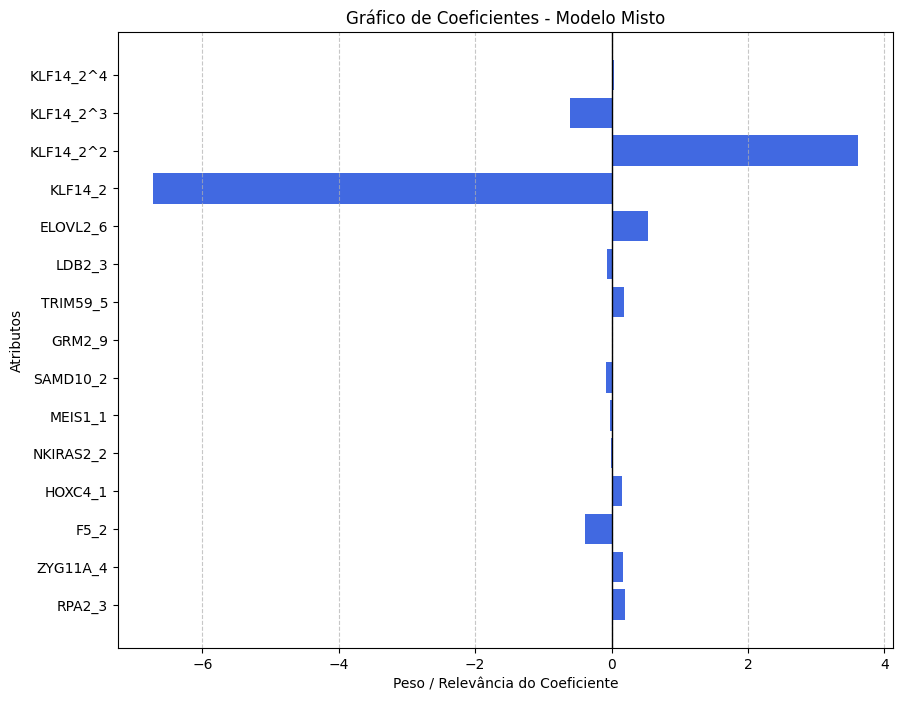

In [ ]:
coeficientes = modelo_misto.coef_[0]
nomes_features = X_train_misto.columns

# gráfico de barras horizontais
plt.figure(figsize=(10, 8))
plt.barh(nomes_features, coeficientes, color='royalblue')
plt.xlabel('Peso / Relevância do Coeficiente')
plt.ylabel('Atributos')
plt.title('Gráfico de Coeficientes - Modelo Misto')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.axvline(0, color='black', linewidth=1)
plt.show()

O atributo ELOVL2_6 destaca-se com a maior barra positiva, o que indica que é o marcador com maior peso e relevância isolada para a previsão.

Atributos como o MEIS1_1, GRM2_9 ou NKIRAS2_2 apresentam barras residuais, quase coladas ao eixo do zero,contribuindo muito pouco de forma isolada para o algoritmo.

Ao dividirmos o KLF14_2 num polinómio de grau 4, o modelo atribui diferentes tamanhos e direções a cada um destes termos. É esta difença entre os coeficientes do polinómio que permite ao modelo moldar a curva para este atributo.